# Week 5 — Multivariate Data & Geospatial Visualization

Completed computational assignment using the supplied synthetic CDB601220 data. Run all cells from this folder. All plots and numerical outputs are retained. **Part C reader collection remains pending:** at least five real participants are required; no responses are fabricated. Optional Part F is not attempted.

Sources: supplied TASKS, DATA_DICTIONARY, geolib.py, vizlib.py and CSV/GeoJSON files, preserved in `original_files/`. Boundary year is unspecified. Discrepancies in the supplied self-checks are reported rather than forced to match. All required computational tasks A, B, C maps, D and E are implemented below.

## Setup and data audit

In [1]:
from pathlib import Path
import json, itertools, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import poisson, chi2
from sklearn.decomposition import PCA
import geolib as g
import vizlib as v
from IPython.display import display, Markdown
ROOT=Path.cwd(); DATA=ROOT/'data'; OUT=ROOT/'figures'; OUT.mkdir(exist_ok=True)
v.style_defaults(dpi=100)
plt.rcParams.update({'font.size':9,'axes.titlesize':11})
h=pd.read_csv(DATA/'health_indicators.csv')
d=pd.read_csv(DATA/'district_health.csv'); d['rate']=d.cases/d.population*1e5
flat=pd.read_csv(DATA/'case05_flat_rates.csv'); flat['rate']=flat.cases/flat.population*1e5
s=pd.read_csv(DATA/'smallarea_cases.csv'); s['rate']=s.cases/s.population*1e5
crime=pd.read_csv(DATA/'county_crime.csv'); crime['rate']=crime.crimes_reported/crime.population*1e5
profiles=pd.read_csv(DATA/'region_profiles.csv'); dense=pd.read_csv(DATA/'scatter_dense.csv')
feats=g.read_geojson(DATA/'districts.geojson')
cols=['gdp_pc','healthcare_access','urban_pct','median_age','cases_per_100k']
chain=g.corr_chain(h,cols)
SOURCE='Synthetic CDB601220 Week 5 data; supplied boundaries, year unspecified; accessed 28 Oct 2026.'
MAPNOTE='Lambert cylindrical equal-area; shared reference latitude. No units suppressed unless stated.'
audit=pd.DataFrame([{'file':p.name,'rows':len(pd.read_csv(p)), 'missing_cells':int(pd.read_csv(p).isna().sum().sum())} for p in DATA.glob('*.csv')])
display(audit)
assert h.country.is_unique and d.code.is_unique
assert set(d.code)=={f['code'] for f in feats}
print('District join: 24 matched, 0 data failures, 0 unmatched polygons. No rows removed.')
def finish(fig,name,note=''):
    fig.text(.01,.005, SOURCE+'\n'+note,fontsize=7,va='bottom')
    fig.tight_layout(rect=(0,.065,1,1))
    if name.startswith('partC_map_'): fig.axes[0].set_position([.08,.15,.52,.72])
    v.save_fig(fig,OUT/(name+'.png'))
    from IPython.display import Image as DisplayImage
    display(DisplayImage(filename=str(OUT/(name+'.png')),width=900))
    plt.close(fig)
def mapplot(ax,frame,value,title,scheme='natural',fs=None):
    fs=feats if fs is None else fs
    edges=g.choropleth(ax,fs,dict(zip(frame.code,frame[value])),scheme=scheme,k=5,cmap='Blues',fmt='{:,.2f}',legend_title=title,legend_anchor=(1,1))
    return edges
notes={}
def diagnose(n,text):
    notes[n]=text
    display(Markdown(text))
# Range-limited, affine area encoding; disclosed because area ratios are compressed.
lo,hi=24.,650.
def bubble_size(pop): return lo+(np.asarray(pop)-h.pop_m.min())/(h.pop_m.max()-h.pop_m.min())*(hi-lo)
def bubble(ax):
    colors=['#0072B2','#D55E00','#009E73','#CC79A7','#E69F00','#555555']
    for reg,col in zip(sorted(h.region.unique()),colors):
        z=h[h.region==reg]; ax.scatter(z.gdp_pc,z.healthcare_access,s=bubble_size(z.pop_m),c=col,label=reg,alpha=.7,edgecolors='white',linewidths=.5)
    ax.set(xscale='log',ylim=(0,100),xlabel='GDP per capita (USD, log scale)',ylabel='Healthcare access (0–100)')
    leg=ax.legend(title='Region',loc='upper left',bbox_to_anchor=(1.01,1)); ax.add_artist(leg)
    refs=[h.pop_m.min(),h.pop_m.median(),h.pop_m.max()]
    handles=[ax.scatter([],[],s=bubble_size(x),c='#888888',label=f'{x:g} M') for x in refs]
    ax.legend(handles=handles,title='Population (million)\nAffine area: 24–650 pt²',loc='lower left',bbox_to_anchor=(1.01,0),labelspacing=2)
    ix=set([h.gdp_pc.idxmax(),h.pop_m.idxmax(),h.healthcare_access.idxmin(),h.healthcare_access.idxmax()])
    for i in ix: ax.annotate(h.loc[i,'country'],(h.loc[i,'gdp_pc'],h.loc[i,'healthcare_access']),xytext=(4,5),textcoords='offset points',fontsize=8)
def rankpcp(ax):
    g.pcp(ax,h,chain,how='rank',highlight=h.region.eq('Andara'))
    ax.set_title('Access and incidence oppose each other; Andara highlighted\nPercentile ranks: robust to GDP outlier; grey = other regions',fontsize=10)
    ax.set_ylabel('Percentile rank (0–1); endpoint labels show raw extrema')

District join: 24 matched, 0 data failures, 0 unmatched polygons. No rows removed.


,file,rows,missing_cells
0,health_indicators.csv,60,0
1,smallarea_cases.csv,40,0
2,county_crime.csv,20,0
3,region_profiles.csv,6,0
4,district_health.csv,24,0
5,case05_flat_rates.csv,24,0
6,scatter_dense.csv,9000,0


## Part A1 — Squared population inflates the size channel

Marks: 60 actual area ratio: 346921.0 under 1 pt²: 3 population <2 M: 9


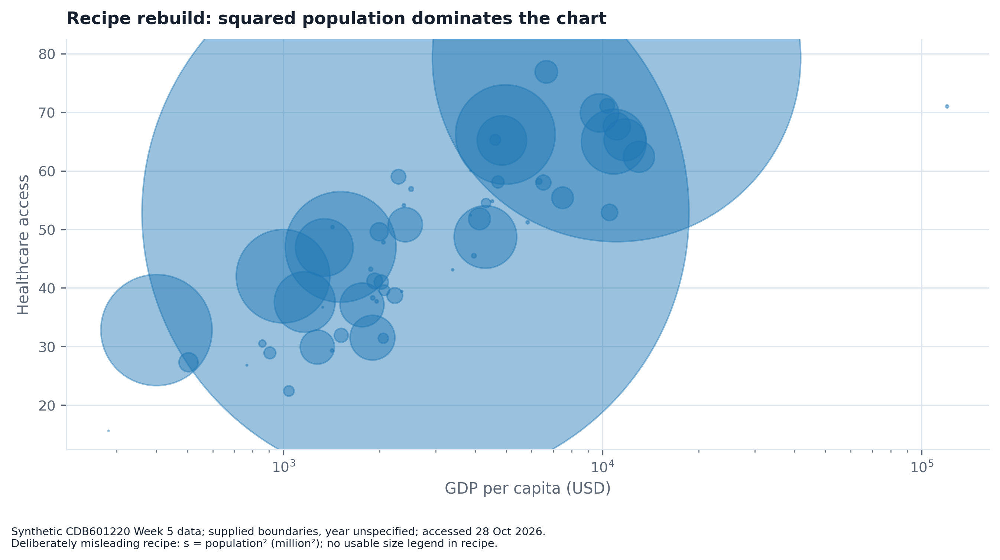

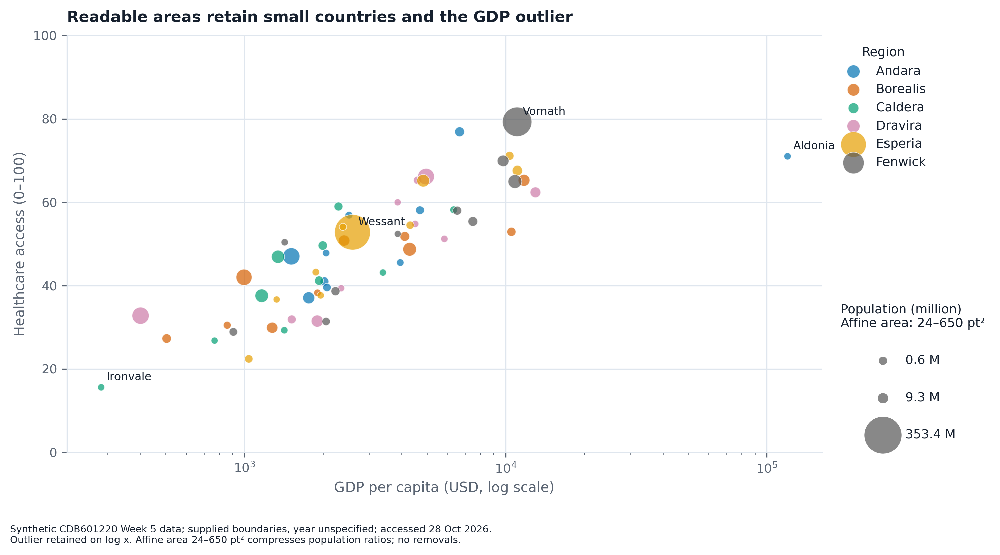

Conclusion: population seems unrelated to access because large marks appear everywhere. Decoy: a linear GDP axis is not the cause; the recipe already specifies log GDP. Mechanism: s is area, so squaring population produces an area ratio of 346,921, not the brief’s 589. The latter is the population ratio. Only 3 marks are below one point-squared; 9 are below 2 M. The supplied self-check mixes these thresholds. Redesign: bounded affine areas with a calibrated legend, log GDP and a full table for exact values; the bounded range is a readability trade-off, not proportional population area.

In [2]:
fig,ax=plt.subplots(figsize=(9,5))
ax.scatter(h.gdp_pc,h.healthcare_access,s=h.pop_m**2,alpha=.45)
ax.set(xscale='log',xlabel='GDP per capita (USD)',ylabel='Healthcare access',title='Recipe rebuild: squared population dominates the chart')
finish(fig,'A01_original','Deliberately misleading recipe: s = population² (million²); no usable size legend in recipe.')
ratio=(h.pop_m.max()/h.pop_m.min())**2
print('Marks:',len(h),'actual area ratio:',ratio,'under 1 pt²:',int((h.pop_m**2<1).sum()),'population <2 M:',int((h.pop_m<2).sum()))
fig,ax=plt.subplots(figsize=(10,5.5)); bubble(ax); ax.set_title('Readable areas retain small countries and the GDP outlier')
finish(fig,'A01_redesign','Outlier retained on log x. Affine area 24–650 pt² compresses population ratios; no removals.')
diagnose(1,f'Conclusion: population seems unrelated to access because large marks appear everywhere. Decoy: a linear GDP axis is not the cause; the recipe already specifies log GDP. Mechanism: s is area, so squaring population produces an area ratio of {ratio:,.0f}, not the brief’s 589. The latter is the population ratio. Only {(h.pop_m**2<1).sum()} marks are below one point-squared; {(h.pop_m<2).sum()} are below 2 M. The supplied self-check mixes these thresholds. Redesign: bounded affine areas with a calibrated legend, log GDP and a full table for exact values; the bounded range is a readability trade-off, not proportional population area.')

## Part A2 — Count is not individual risk

Total cases/population: 30564 57857000
Top count: ['D17', 'D13', 'D09'] Top rate: ['D19', 'D20', 'D21']


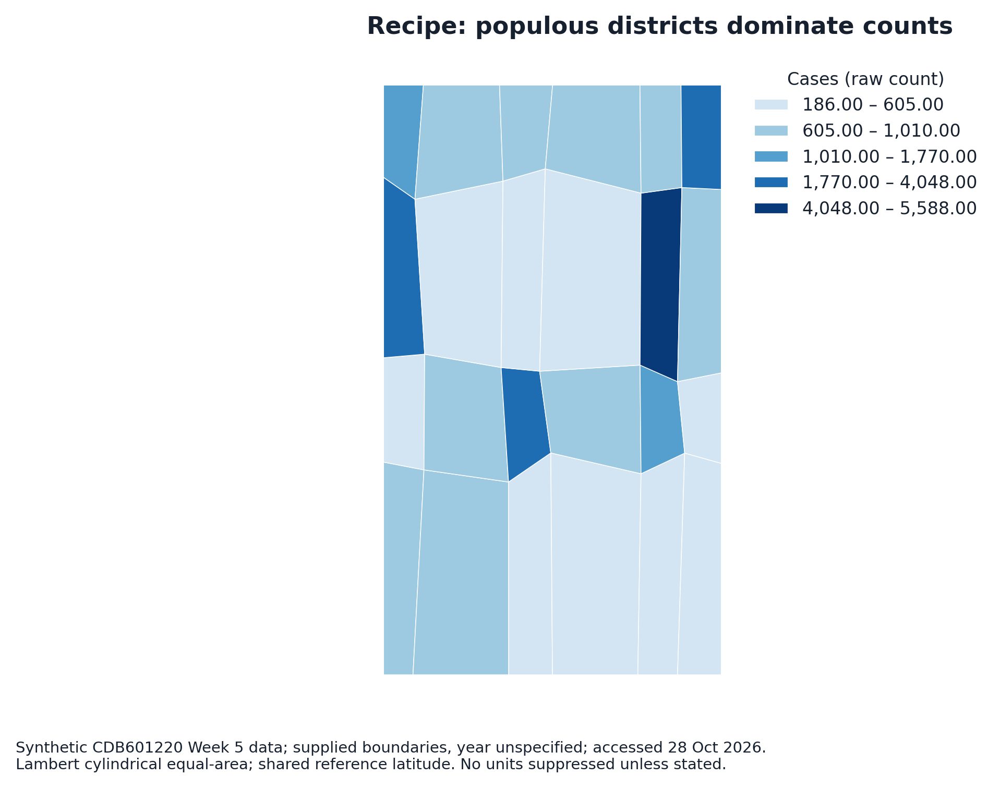

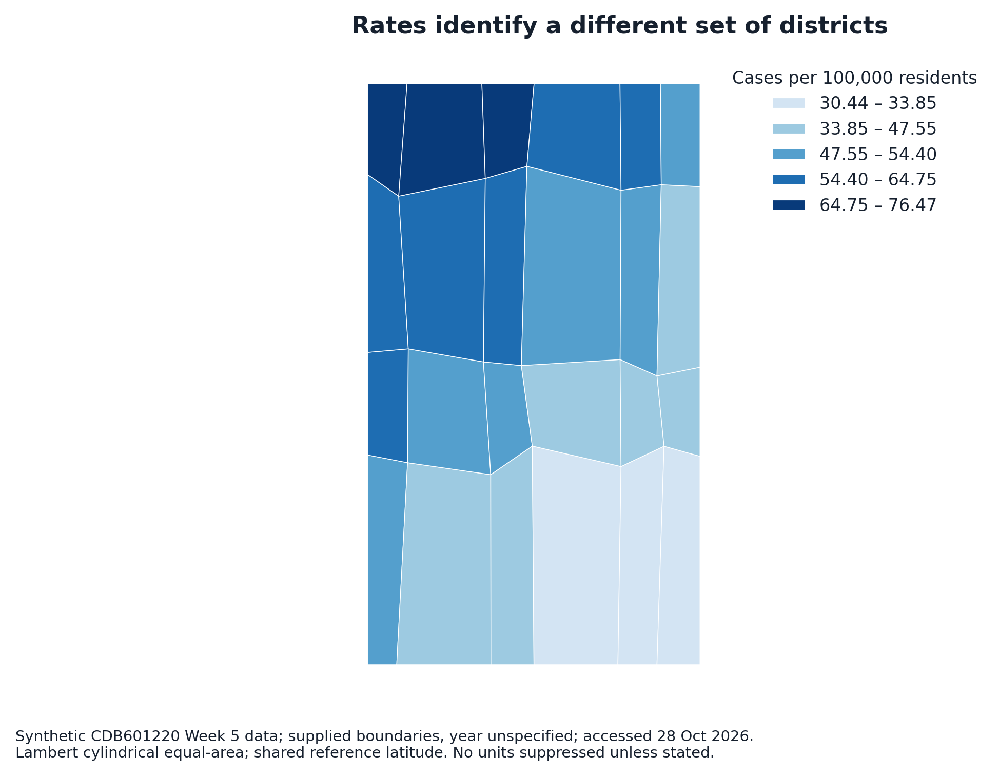

Conclusion: the capital-area districts have the greatest outbreak risk. Decoy: failed joins cannot explain this; all 24 codes match and all counts are retained. Mechanism: population is the hidden denominator. Counts correlate with population at r=0.986. Count leaders D17, D13 and D09 are replaced by rate leaders D19, D20 and D21. Counts remain relevant for workload; rates answer relative risk. Total: 30,564 cases in 57,857,000 residents.

In [3]:
fig,ax=plt.subplots(figsize=(7,5)); mapplot(ax,d,'cases','Cases (raw count)'); ax.set_title('Recipe: populous districts dominate counts'); finish(fig,'A02_original',MAPNOTE)
fig,ax=plt.subplots(figsize=(7,5)); mapplot(ax,d,'rate','Cases per 100,000 residents'); ax.set_title('Rates identify a different set of districts'); finish(fig,'A02_redesign',MAPNOTE)
print('Total cases/population:',d.cases.sum(),d.population.sum()); print('Top count:',d.nlargest(3,'cases').code.tolist(),'Top rate:',d.nlargest(3,'rate').code.tolist())
diagnose(2,f'Conclusion: the capital-area districts have the greatest outbreak risk. Decoy: failed joins cannot explain this; all 24 codes match and all counts are retained. Mechanism: population is the hidden denominator. Counts correlate with population at r={d.cases.corr(d.population):.3f}. Count leaders D17, D13 and D09 are replaced by rate leaders D19, D20 and D21. Counts remain relevant for workload; rates answer relative risk. Total: {d.cases.sum():,} cases in {d.population.sum():,} residents.')

## Part A3 — A single extreme GDP compresses min–max scaling

Below 0.10: 58 Median: 0.017371764941302027 GDP range: 283 120219


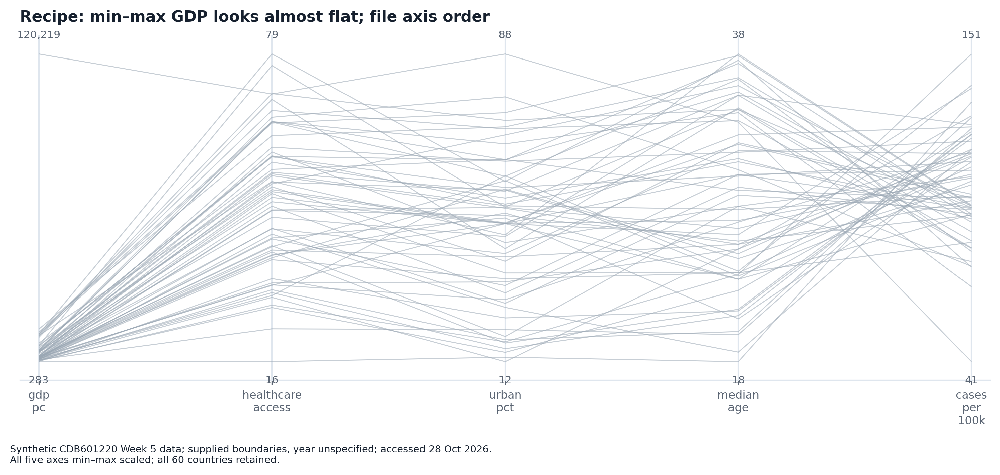

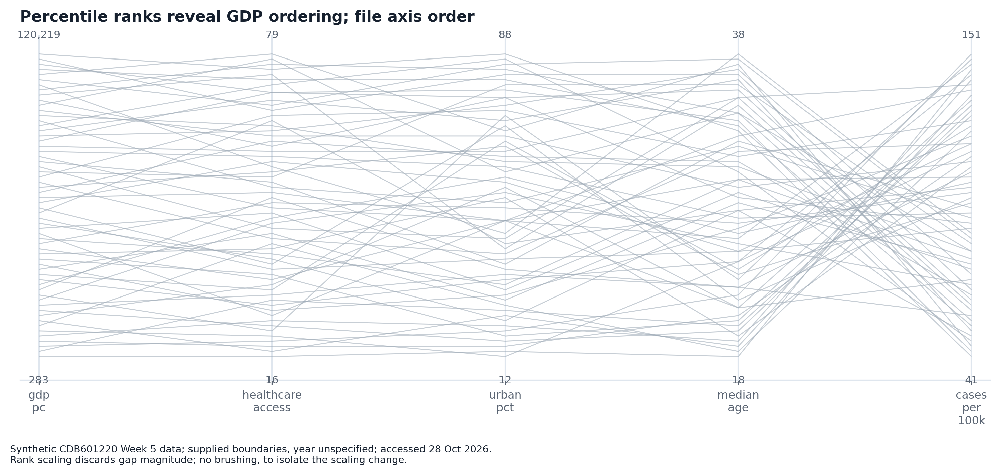

Conclusion: GDP hardly varies. Decoy: GDP does not have a narrow raw range; it spans $283–$120,219. Mechanism: the largest observation controls the min–max denominator, leaving 58 of 60 countries below 0.10 and the median at 0.017. Rank scaling makes order visible without deleting the outlier, while sacrificing distances between observations.

In [4]:
fig,ax=plt.subplots(figsize=(10,4.7)); g.pcp(ax,h,cols,'minmax'); ax.set_title('Recipe: min–max GDP looks almost flat; file axis order'); finish(fig,'A03_original','All five axes min–max scaled; all 60 countries retained.')
fig,ax=plt.subplots(figsize=(10,4.7)); g.pcp(ax,h,cols,'rank'); ax.set_title('Percentile ranks reveal GDP ordering; file axis order'); finish(fig,'A03_redesign','Rank scaling discards gap magnitude; no brushing, to isolate the scaling change.')
mm=g.scale_frame(h,cols,'minmax').gdp_pc
print('Below 0.10:',(mm<.1).sum(),'Median:',mm.median(),'GDP range:',h.gdp_pc.min(),h.gdp_pc.max())
diagnose(3,f'Conclusion: GDP hardly varies. Decoy: GDP does not have a narrow raw range; it spans ${h.gdp_pc.min():,}–${h.gdp_pc.max():,}. Mechanism: the largest observation controls the min–max denominator, leaving {(mm<.1).sum()} of 60 countries below 0.10 and the median at {mm.median():.3f}. Rank scaling makes order visible without deleting the outlier, while sacrificing distances between observations.')

## Part A4 — Nonadjacent axes hide a relationship

Computed chain: ['healthcare_access', 'cases_per_100k', 'urban_pct', 'median_age', 'gdp_pc']


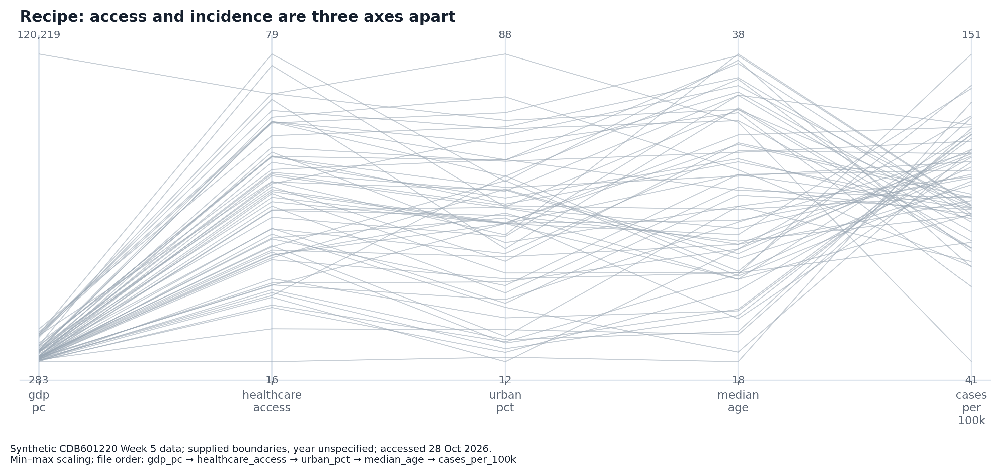

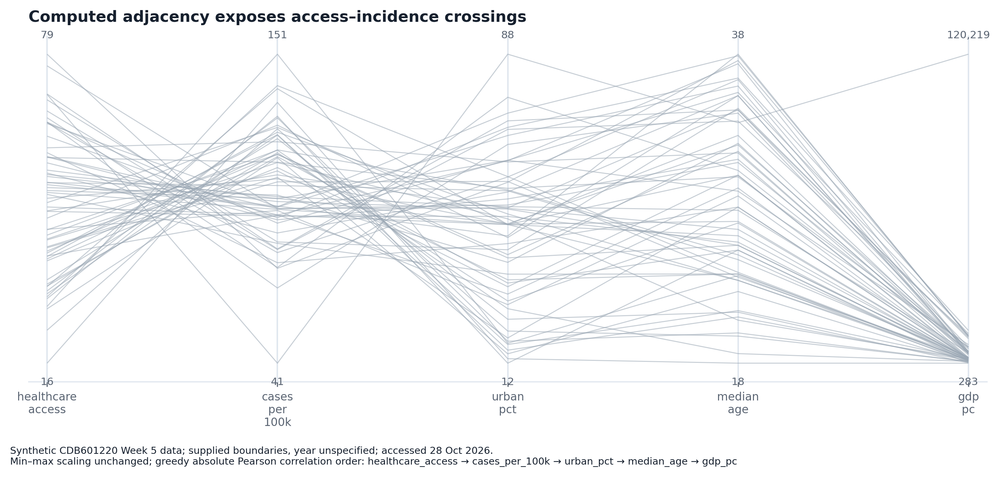

,gdp_pc,healthcare_access,urban_pct,median_age,cases_per_100k
gdp_pc,1.000,0.365,0.436,0.281,-0.520
healthcare_access,0.365,1.000,0.754,0.796,-0.799
urban_pct,0.436,0.754,1.000,0.644,-0.619
median_age,0.281,0.796,0.644,1.000,-0.587
cases_per_100k,-0.520,-0.799,-0.619,-0.587,1.000


Conclusion: access and incidence are unrelated. Decoy: lack of numerical association is ruled out by r=-0.799. Mechanism: their file-order positions differ by three; a crossing can only be read locally between adjacent axes. The computed greedy order puts them together while holding min–max scaling constant. The inverse relationship now produces an X-shaped waist.

In [5]:
fig,ax=plt.subplots(figsize=(10,4.7)); g.pcp(ax,h,cols,'minmax'); ax.set_title('Recipe: access and incidence are three axes apart'); finish(fig,'A04_original','Min–max scaling; file order: '+' → '.join(cols))
fig,ax=plt.subplots(figsize=(10,4.7)); g.pcp(ax,h,chain,'minmax'); ax.set_title('Computed adjacency exposes access–incidence crossings'); finish(fig,'A04_redesign','Min–max scaling unchanged; greedy absolute Pearson correlation order: '+' → '.join(chain))
print('Computed chain:',chain); display(h[cols].corr().round(3))
diagnose(4,f'Conclusion: access and incidence are unrelated. Decoy: lack of numerical association is ruled out by r={h.healthcare_access.corr(h.cases_per_100k):.3f}. Mechanism: their file-order positions differ by three; a crossing can only be read locally between adjacent axes. The computed greedy order puts them together while holding min–max scaling constant. The inverse relationship now produces an X-shaped waist.')

## Part A5 — Quantile bins manufacture contrast

Quantile edges: [np.float64(31.074168797953966), np.float64(31.487666463180265), np.float64(32.068680981056545), np.float64(32.51031458057807), np.float64(32.93761959433601), np.float64(33.39920948616601)] rate min/max: 31.074168797953966 33.39920948616601 spread %: 7.2085211977650205


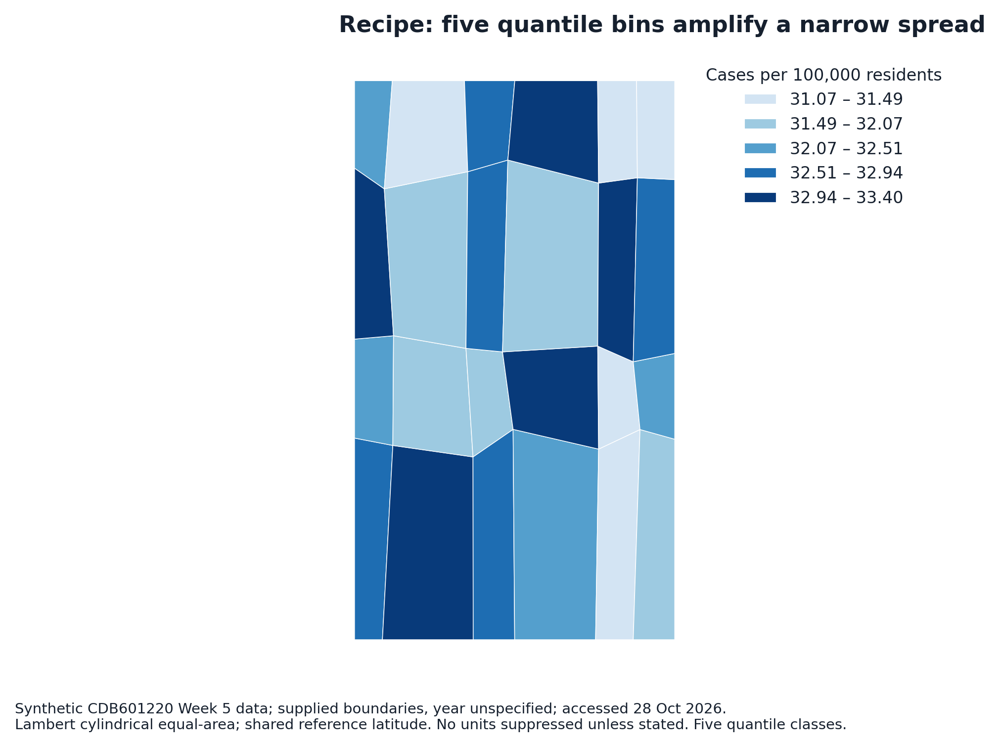

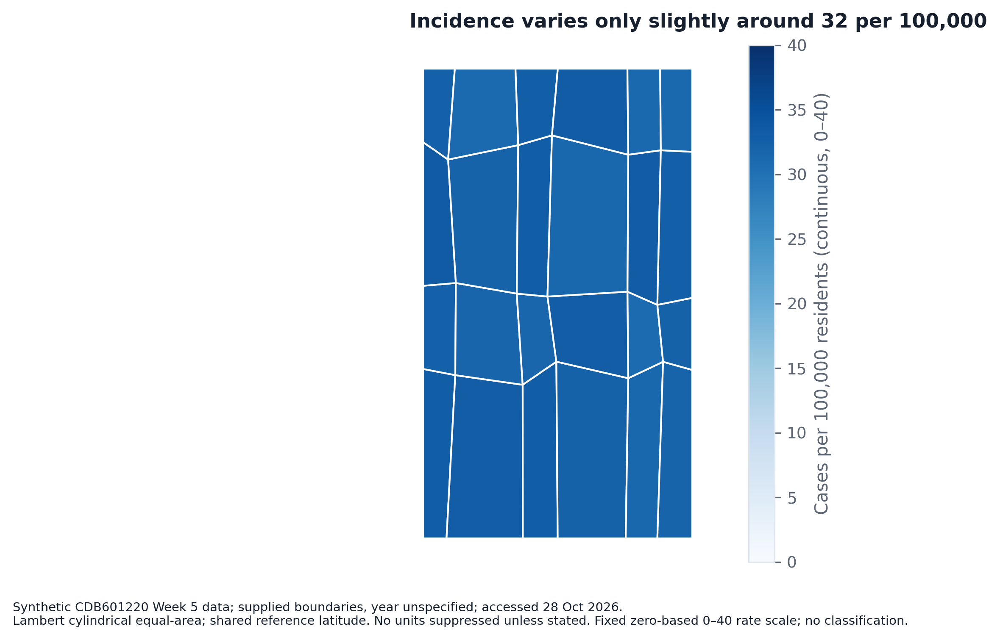

Conclusion: five distinct incidence levels form a strong gradient. Decoy: the sequential blue palette is appropriate; rainbow hue is not the problem. Mechanism: quantiles force approximately equal occupancy across five colours even though rates span 31.07–33.40, only 7.2% of the mean. A fixed continuous 0–40 scale preserves the small magnitude. Class membership is not evidence of five real risk regimes.

In [6]:
fig,ax=plt.subplots(figsize=(7,5)); edges=mapplot(ax,flat,'rate','Cases per 100,000 residents','quantile'); ax.set_title('Recipe: five quantile bins amplify a narrow spread'); finish(fig,'A05_original',MAPNOTE+' Five quantile classes.')
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon
from matplotlib.colors import Normalize
fig,ax=plt.subplots(figsize=(7,5)); patches=[]
lat_ts=np.mean([p[1] for f in feats for p in f['ring']]); vals=flat.set_index('code').rate
for f in feats:
    x,y=g.equal_area_xy(*zip(*f['ring']),lat_ts=lat_ts); patches.append(Polygon(np.c_[x,y]))
pc=PatchCollection(patches,cmap='Blues',norm=Normalize(0,40),edgecolor='white'); pc.set_array(np.array([vals[f['code']] for f in feats])); ax.add_collection(pc); ax.autoscale_view(); ax.set_aspect('equal'); ax.axis('off')
fig.colorbar(pc,ax=ax,label='Cases per 100,000 residents (continuous, 0–40)'); ax.set_title('Incidence varies only slightly around 32 per 100,000'); finish(fig,'A05_redesign',MAPNOTE+' Fixed zero-based 0–40 rate scale; no classification.')
print('Quantile edges:',edges,'rate min/max:',flat.rate.min(),flat.rate.max(),'spread %:',flat.rate.ptp() if hasattr(flat.rate,'ptp') else np.ptp(flat.rate)/flat.rate.mean()*100)
diagnose(5,f'Conclusion: five distinct incidence levels form a strong gradient. Decoy: the sequential blue palette is appropriate; rainbow hue is not the problem. Mechanism: quantiles force approximately equal occupancy across five colours even though rates span {flat.rate.min():.2f}–{flat.rate.max():.2f}, only {np.ptp(flat.rate)/flat.rate.mean()*100:.1f}% of the mean. A fixed continuous 0–40 scale preserves the small magnitude. Class membership is not evidence of five real risk regimes.')

## Part A6 — Small denominators produce noisy extremes

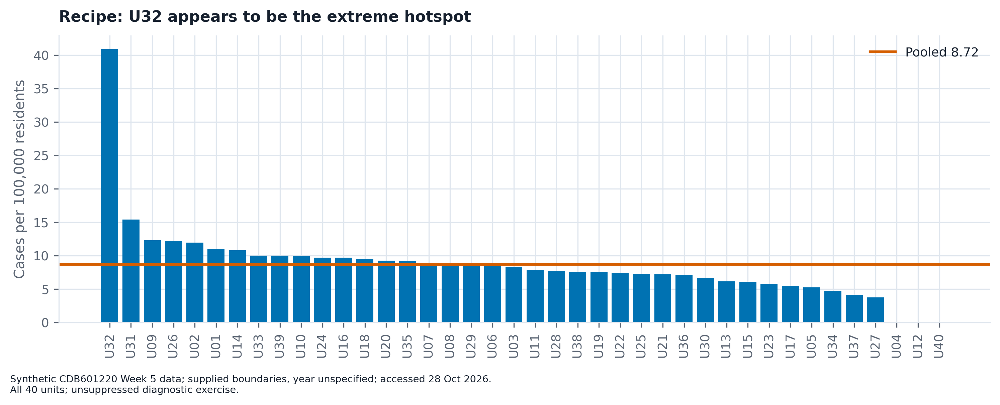

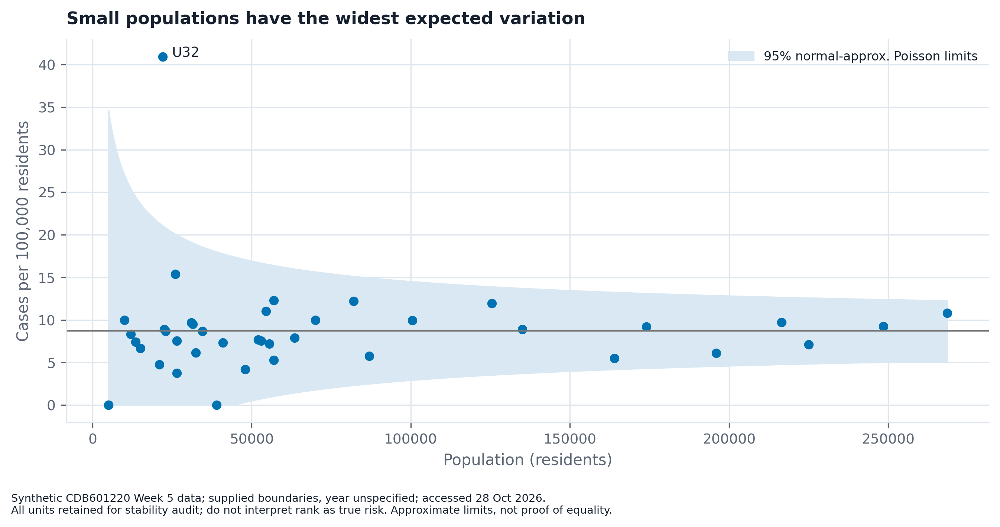

Conclusion: U32 has almost five times the true risk. Decoy: the arithmetic is correct: 9/22000 × 100,000 = 40.9, versus pooled 8.72. Mechanism: random-count variance divided by a small population gives highly unstable rates. The data dictionary explicitly states every unit has the same true rate. U32 has only nine observed cases. A funnel communicates expected uncertainty; even an outlier warrants investigation rather than a causal hotspot label. No observations are removed from this diagnostic chart.

In [7]:
pooled=s.cases.sum()/s.population.sum()*1e5
fig,ax=plt.subplots(figsize=(10,4)); z=s.sort_values('rate',ascending=False); ax.bar(z.iloc[:,0],z.rate,color='#0072B2'); ax.axhline(pooled,color='#D55E00',label=f'Pooled {pooled:.2f}'); ax.tick_params(axis='x',rotation=90); ax.legend(); ax.set(ylabel='Cases per 100,000 residents',title='Recipe: U32 appears to be the extreme hotspot'); finish(fig,'A06_original','All 40 units; unsuppressed diagnostic exercise.')
def funnel(ax):
    grid=np.geomspace(s.population.min(),s.population.max(),400); lim=g.funnel_limits(grid,pooled)
    ax.fill_between(lim.population,lim.lo,lim.hi,color='#d9e8f2',label='95% normal-approx. Poisson limits')
    ax.axhline(pooled,color='#777777',lw=1); ax.scatter(s.population,s.rate,c='#0072B2',s=26)
    u=s.iloc[s.rate.argmax()]; ax.annotate(str(u.iloc[0]),(u.population,u.rate),xytext=(6,0),textcoords='offset points')
    ax.set(xlabel='Population (residents)',ylabel='Cases per 100,000 residents',title='Small populations have the widest expected variation'); ax.legend(fontsize=8)
fig,ax=plt.subplots(figsize=(9,4.7)); funnel(ax); finish(fig,'A06_redesign','All units retained for stability audit; do not interpret rank as true risk. Approximate limits, not proof of equality.')
u=s.iloc[s.rate.argmax()]
diagnose(6,f'Conclusion: U32 has almost five times the true risk. Decoy: the arithmetic is correct: {u.cases:g}/{u.population:g} × 100,000 = {u.rate:.1f}, versus pooled {pooled:.2f}. Mechanism: random-count variance divided by a small population gives highly unstable rates. The data dictionary explicitly states every unit has the same true rate. U32 has only nine observed cases. A funnel communicates expected uncertainty; even an outlier warrants investigation rather than a causal hotspot label. No observations are removed from this diagnostic chart.')

## Part A7 — Correlation depends on the aggregation boundaries

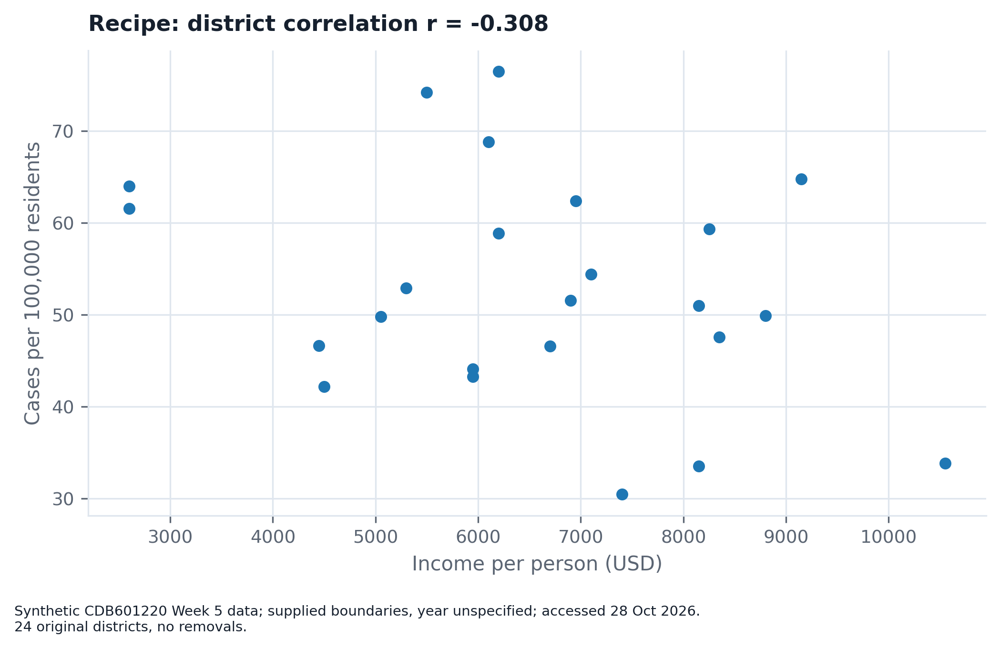

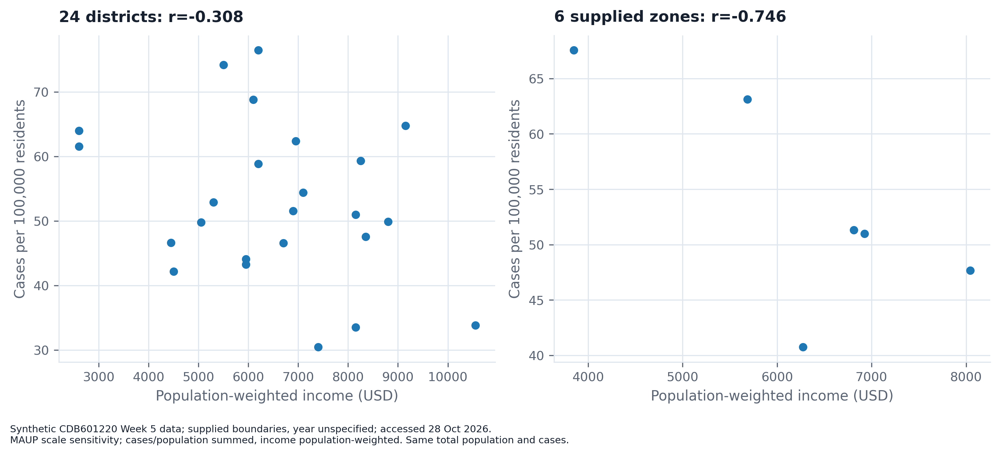

,zone,income,rate,population,cases
0,P1,6813.267754,51.311580,6252000,3208
1,P2,8044.638199,47.666892,10351000,4934
2,P3,6272.680930,40.738082,6964000,2837
3,P4,3849.713309,67.548536,9941000,6715
4,P5,5686.214644,63.124504,3783000,2388
5,P6,6923.529126,50.967616,20566000,10482


Conclusion: income and incidence are intrinsically weakly related. Decoy: mismatched totals are ruled out; aggregation conserves all 30,564 cases and 57,857,000 residents. Mechanism: the modifiable areal unit problem (MAUP). Correlation changes from -0.308 for 24 districts to -0.746 for six supplied zones. Rates are recomputed from pooled counts, never averaged unweighted. The alternate 24-unit GeoJSON has no corresponding observations or crosswalk; exact alternative-zone rates cannot be inferred without an allocation assumption. No areal interpolation is presented as measured data, and neither aggregate correlation establishes individual risk.

In [8]:
coarse=g.read_geojson(DATA/'districts_coarse.geojson')
rows=[]
for f in coarse:
    z=d[d.code.isin(f['members'].split(','))]
    rows.append({'zone':f['code'],'income':np.average(z.income_pc_usd,weights=z.population),'rate':z.cases.sum()/z.population.sum()*1e5,'population':z.population.sum(),'cases':z.cases.sum()})
zones=pd.DataFrame(rows)
fig,ax=plt.subplots(figsize=(7,4.5)); ax.scatter(d.income_pc_usd,d.rate); ax.set(xlabel='Income per person (USD)',ylabel='Cases per 100,000 residents',title=f'Recipe: district correlation r = {d.income_pc_usd.corr(d.rate):.3f}'); finish(fig,'A07_original','24 original districts, no removals.')
fig,axs=plt.subplots(1,2,figsize=(10,4.5))
axs[0].scatter(d.income_pc_usd,d.rate); axs[1].scatter(zones.income,zones.rate)
for ax in axs: ax.set(xlabel='Population-weighted income (USD)',ylabel='Cases per 100,000 residents')
axs[0].set_title(f'24 districts: r={d.income_pc_usd.corr(d.rate):.3f}'); axs[1].set_title(f'6 supplied zones: r={zones.income.corr(zones.rate):.3f}')
finish(fig,'A07_redesign','MAUP scale sensitivity; cases/population summed, income population-weighted. Same total population and cases.')
assert zones.cases.sum()==d.cases.sum() and zones.population.sum()==d.population.sum()
display(zones)
diagnose(7,f'Conclusion: income and incidence are intrinsically weakly related. Decoy: mismatched totals are ruled out; aggregation conserves all {d.cases.sum():,} cases and {d.population.sum():,} residents. Mechanism: the modifiable areal unit problem (MAUP). Correlation changes from {d.income_pc_usd.corr(d.rate):.3f} for 24 districts to {zones.income.corr(zones.rate):.3f} for six supplied zones. Rates are recomputed from pooled counts, never averaged unweighted. The alternate 24-unit GeoJSON has no corresponding observations or crosswalk; exact alternative-zone rates cannot be inferred without an allocation assumption. No areal interpolation is presented as measured data, and neither aggregate correlation establishes individual risk.')

## Part A8 — Land area is not population at risk

Top-five population land/pop shares: 0.12593402078172483 0.5988039476640683
Top-two classes land/pop/case shares: 0.31195343886302224 0.2649290492075289 0.3298652008899359


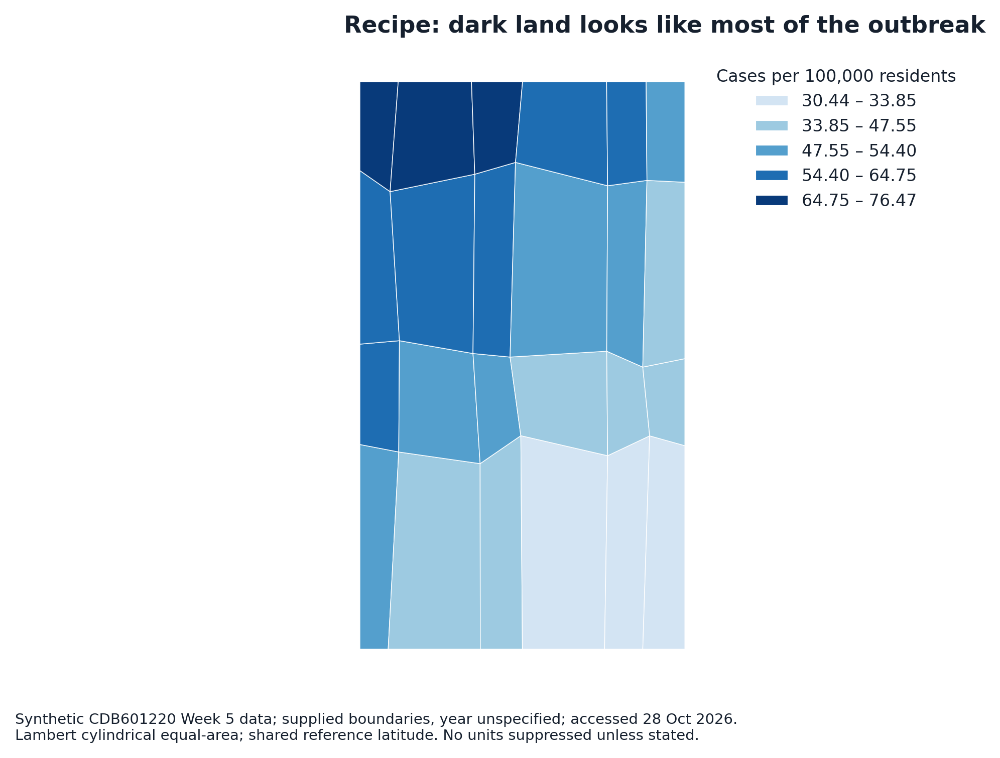

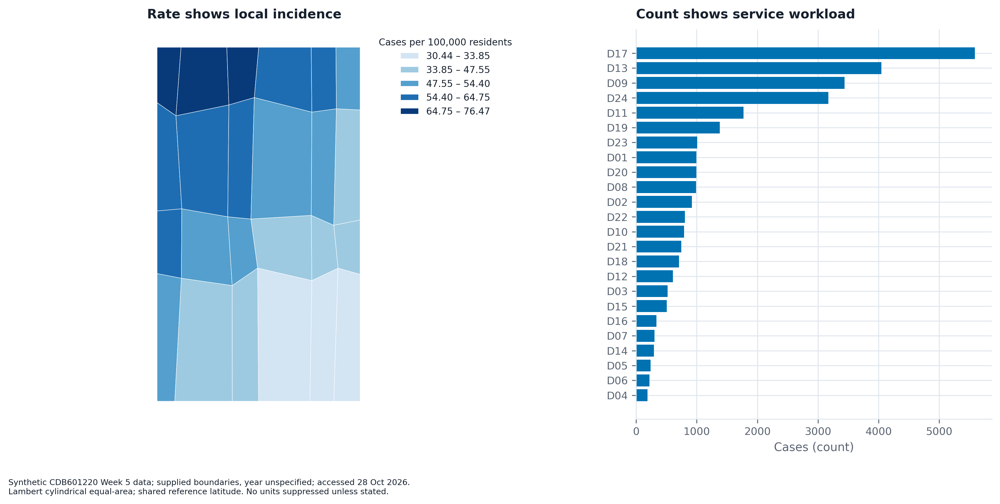

Conclusion: a rural outbreak dominates because much of the map is dark. Decoy: raw counts are not the cause here; this recipe already maps rates correctly. Mechanism: large rural polygons occupy visual area disproportionate to their population. The five largest populations account for 12.6% of land and 59.9% of residents. A rate map plus a zero-based sorted count bar separates risk from workload. Darkness over land does not establish the fraction of patients living there.

In [9]:
fig,ax=plt.subplots(figsize=(7,5)); e=mapplot(ax,d,'rate','Cases per 100,000 residents'); ax.set_title('Recipe: dark land looks like most of the outbreak'); finish(fig,'A08_original',MAPNOTE)
fig,axs=plt.subplots(1,2,figsize=(12,6),gridspec_kw={'width_ratios':[1.4,1]}); mapplot(axs[0],d,'rate','Cases per 100,000 residents'); z=d.sort_values('cases'); axs[1].barh(z.code,z.cases,color='#0072B2'); axs[1].set(xlabel='Cases (count)',title='Count shows service workload'); axs[0].set_title('Rate shows local incidence'); fig.subplots_adjust(wspace=.7); finish(fig,'A08_redesign',MAPNOTE)
top=d.nlargest(5,'population'); cl=g.class_of(d.rate,e); high=d[cl>=3]
print('Top-five population land/pop shares:',top.area_km2.sum()/d.area_km2.sum(),top.population.sum()/d.population.sum()); print('Top-two classes land/pop/case shares:',*[high[c].sum()/d[c].sum() for c in ['area_km2','population','cases']])
diagnose(8,f'Conclusion: a rural outbreak dominates because much of the map is dark. Decoy: raw counts are not the cause here; this recipe already maps rates correctly. Mechanism: large rural polygons occupy visual area disproportionate to their population. The five largest populations account for {top.area_km2.sum()/d.area_km2.sum():.1%} of land and {top.population.sum()/d.population.sum():.1%} of residents. A rate map plus a zero-based sorted count bar separates risk from workload. Darkness over land does not establish the fraction of patients living there.')

## Part A9 — Radar area depends on arbitrary axis order

Means: 62.29999999999999 61.96666666666667 areas: 9933.402314074907 9432.748698020107 area difference over orders: -1130.7910203564388 1658.6291738360324 A wins: 78 of 120


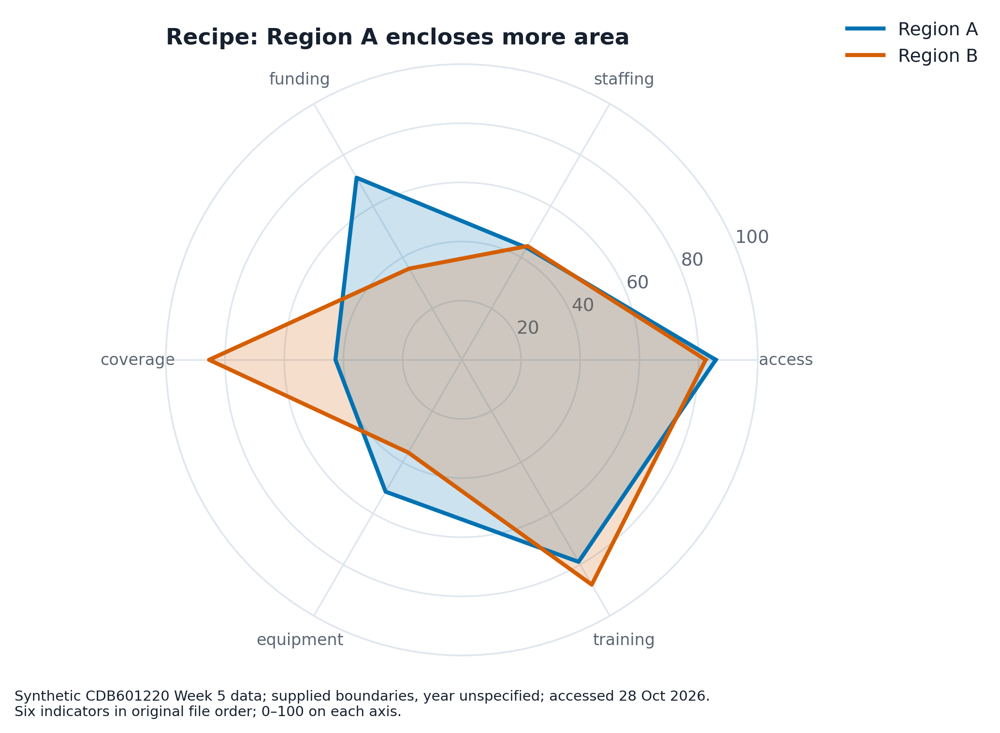

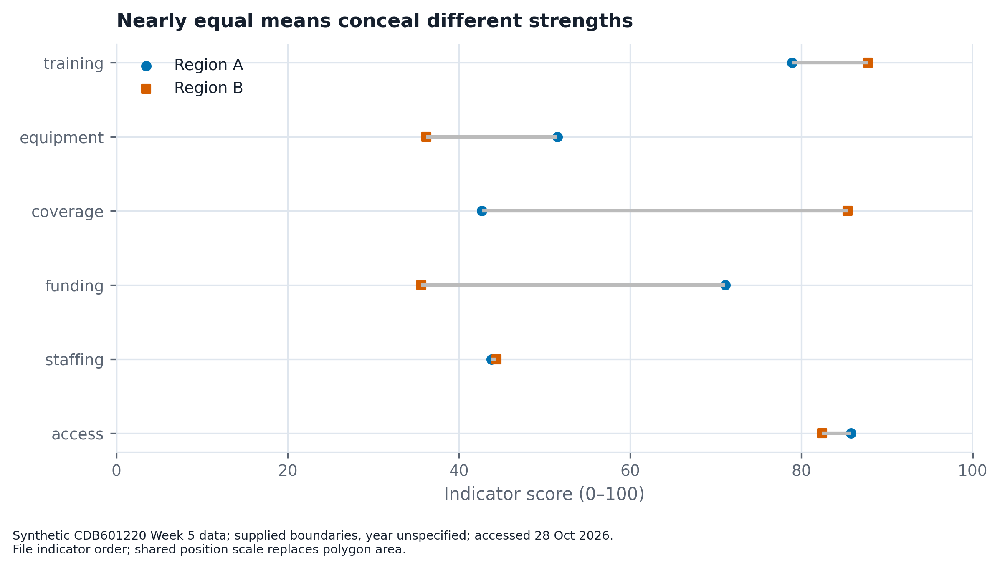

Conclusion: Region A is stronger overall. Decoy: different measurement scales are ruled out; all six scores share 0–100, with means 62.30 and 61.97. Mechanism: radar area sums adjacent products, so arbitrary order changes area without changing any score. Original areas are 9,933 and 9,433; over 120 rotation-fixed orders A-minus-B ranges from -1,131 to 1,659, reversing the apparent winner. Aligned dots permit accurate per-indicator comparison; a single overall winner requires explicit weights.

In [10]:
a=profiles.region_a.to_numpy(); b=profiles.region_b.to_numpy()
def radar_area(x): return .5*np.sin(2*np.pi/len(x))*np.sum(x*np.roll(x,-1))
theta=np.linspace(0,2*np.pi,6,endpoint=False)
fig,ax=plt.subplots(figsize=(7,5),subplot_kw={'projection':'polar'})
for x,c,label in [(a,'#0072B2','Region A'),(b,'#D55E00','Region B')]:
    ax.plot(np.r_[theta,theta[0]],np.r_[x,x[0]],c=c,label=label); ax.fill(np.r_[theta,theta[0]],np.r_[x,x[0]],c=c,alpha=.2)
ax.set_xticks(theta); ax.set_xticklabels(profiles.indicator,fontsize=8); ax.set_ylim(0,100); ax.legend(loc='upper right',bbox_to_anchor=(1.4,1.1)); ax.set_title('Recipe: Region A encloses more area'); finish(fig,'A09_original','Six indicators in original file order; 0–100 on each axis.')
fig,ax=plt.subplots(figsize=(8,4.5)); yy=np.arange(6)
ax.hlines(yy,np.minimum(a,b),np.maximum(a,b),color='#bbbbbb'); ax.scatter(a,yy,c='#0072B2',label='Region A'); ax.scatter(b,yy,c='#D55E00',marker='s',label='Region B'); ax.set_yticks(yy); ax.set_yticklabels(profiles.indicator); ax.set(xlim=(0,100),xlabel='Indicator score (0–100)',title='Nearly equal means conceal different strengths'); ax.legend(); finish(fig,'A09_redesign','File indicator order; shared position scale replaces polygon area.')
perms=[p for p in itertools.permutations(range(6)) if p[0]==0]
diffs=np.array([radar_area(a[list(p)])-radar_area(b[list(p)]) for p in perms])
print('Means:',a.mean(),b.mean(),'areas:',radar_area(a),radar_area(b),'area difference over orders:',diffs.min(),diffs.max(),'A wins:',(diffs>0).sum(),'of',len(perms))
diagnose(9,f'Conclusion: Region A is stronger overall. Decoy: different measurement scales are ruled out; all six scores share 0–100, with means {a.mean():.2f} and {b.mean():.2f}. Mechanism: radar area sums adjacent products, so arbitrary order changes area without changing any score. Original areas are {radar_area(a):,.0f} and {radar_area(b):,.0f}; over 120 rotation-fixed orders A-minus-B ranges from {diffs.min():,.0f} to {diffs.max():,.0f}, reversing the apparent winner. Aligned dots permit accurate per-indicator comparison; a single overall winner requires explicit weights.')

## Part B — Five computed design decisions

B1: affine area range: (24.0, 650.0) pt²; diameter ratio: 5.204164998665331
24 pt² keeps small marks visible; 650 pt² limits overlap. s, not radius, is linear in population.
True proportional 650*population/max would give a minimum area of 1.1035653650254669 pt²; rejected for readability.
B3: GDP under each scaling:
minmax {'min': np.float64(0.0), 'median': np.float64(0.017371764941302027), 'max': np.float64(1.0), 'SD': np.float64(0.12718394113835402), 'below_0.1': 58}
zscore {'min': np.float64(-0.3616324135700138), 'median': np.float64(-0.22504469042024472), 'max': np.float64(7.500995454772058), 'SD': np.float64(0.9999999999999999), 'below_0.1': 50}
rank {'min': np.float64(0.016666666666666666), 'median': np.float64(0.5083333333333333), 'max': np.float64(1.0), 'SD': np.float64(0.28863503804144286), 'below_0.1': 5}
PCA first two explained variance ratios: [0.67504957 0.16162832]
Variance omitted by 2-D PCA: 0.16332211093091697
PCA variance is not information in a causal sense; standard

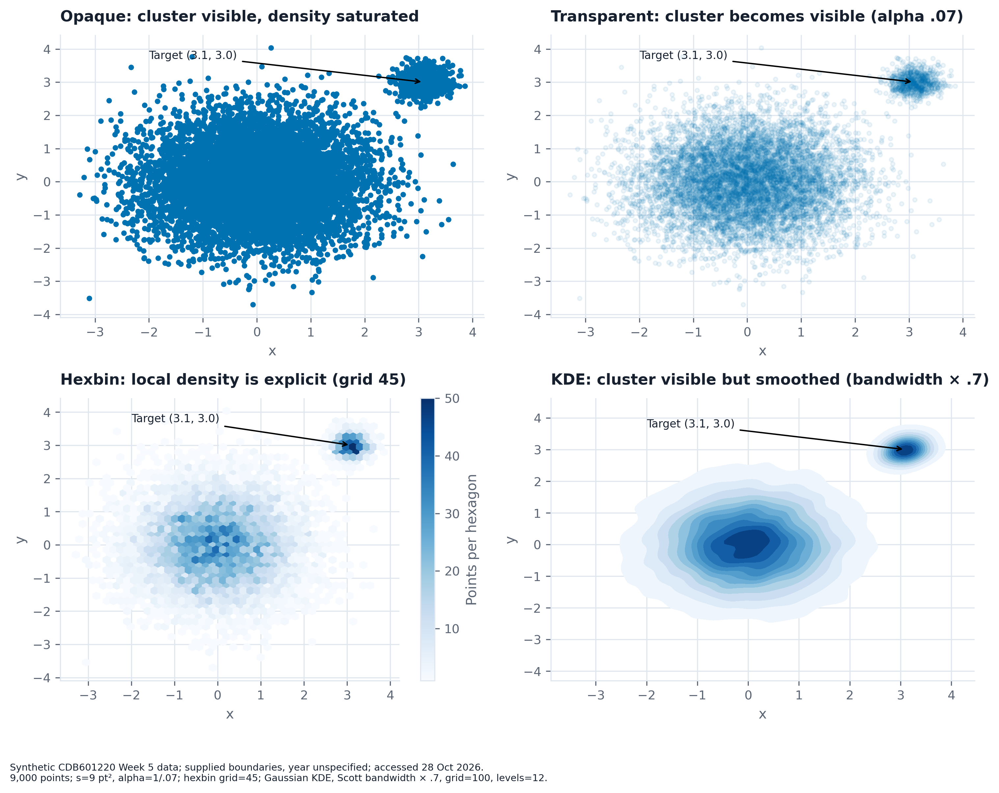

,method,800-point cluster,publish
0,opaque,Visible isolated cluster; internal density sat...,No
1,transparent,Visible density patch,Possible
2,hexbin,Visible dense hexagons,Yes: quantitative count legend
3,KDE,Visible smoothed peak,Supplement: bandwidth sensitive


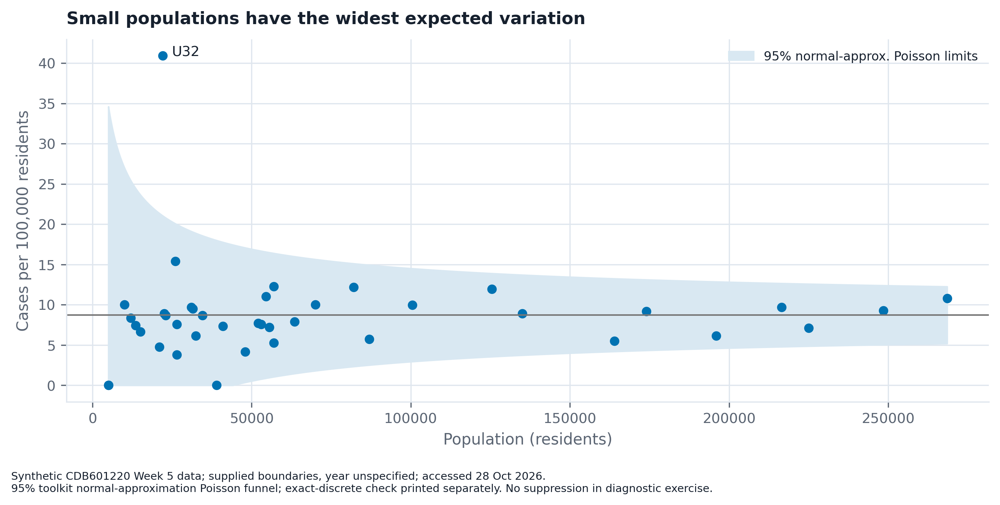

In [11]:
from contextlib import redirect_stdout
import io
report=io.StringIO()
with redirect_stdout(report):
    print('B1: affine area range:',(lo,hi),'pt²; diameter ratio:',np.sqrt(hi/lo))
    print('24 pt² keeps small marks visible; 650 pt² limits overlap. s, not radius, is linear in population.')
    print('True proportional 650*population/max would give a minimum area of',650*h.pop_m.min()/h.pop_m.max(),'pt²; rejected for readability.')
    print('B3: GDP under each scaling:')
    for how in ['minmax','zscore','rank']:
        q=g.scale_frame(h,cols,how).gdp_pc
        print(how,{'min':q.min(),'median':q.median(),'max':q.max(),'SD':q.std(ddof=0),'below_0.1':int((q<.1).sum())})
    pca=PCA().fit(g.scale_frame(h,cols,'zscore'))
    print('PCA first two explained variance ratios:',pca.explained_variance_ratio_[:2])
    print('Variance omitted by 2-D PCA:',1-pca.explained_variance_ratio_[:2].sum())
    print('PCA variance is not information in a causal sense; standardisation weights each variable equally.')
    def shoelace(ring):
        ar=np.asarray(ring); return .5*abs(np.dot(ar[:,0],np.roll(ar[:,1],-1))-np.dot(ar[:,1],np.roll(ar[:,0],-1)))
    ar=pd.DataFrame([{'code':f['code'],'latitude':np.mean(np.array(f['ring'])[:,1]),'sphere_km2':g.polygon_area_km2(f['ring']),'raw_deg2':shoelace(f['ring'])} for f in feats])
    ar['sphere_share']=ar.sphere_km2/ar.sphere_km2.sum(); ar['degree_share']=ar.raw_deg2/ar.raw_deg2.sum(); ar['distortion_pp']=100*(ar.degree_share-ar.sphere_share)
    north=ar.nlargest(4,'latitude')
    print('B4 four northernmost:',north.code.tolist(),'shares spherical/degrees:',north.sphere_share.sum(),north.degree_share.sum())
    print('Largest absolute share distortion:',ar.loc[ar.distortion_pp.abs().idxmax()].to_dict())
    lat=np.array([p[1] for f in feats for p in f['ring']]); inflation=1/np.cos(np.deg2rad([lat.min(),lat.max()]))**2
    print('Mercator local area inflation at south/north edges:',inflation)
    actual=[]
    for f in feats:
        x,y=g.mercator_xy(*zip(*f['ring'])); actual.append(shoelace(np.c_[x,y])/g.polygon_area_km2(f['ring']))
    print('Polygon Mercator/spherical area ratios:',min(actual),max(actual))
    print('Mercator preserves local angles but inflates area by sec(latitude)^2, not sec(latitude) as the supplied comment says; equal-area preserves visual land shares.')
    lim=g.funnel_limits(np.unique(s.population),pooled).set_index('population')
    low=lim.loc[s.population,'lo'].to_numpy(); high=lim.loc[s.population,'hi'].to_numpy()
    outside=(s.rate.to_numpy()<low)|(s.rate.to_numpy()>high)
    print('B5 normal-approximate 95% funnel outliers:',outside.sum(),'of',len(s),s.loc[outside].iloc[:,0].tolist())
    exactlo=poisson.ppf(.025,pooled*s.population/1e5)/s.population*1e5
    exacthi=poisson.ppf(.975,pooled*s.population/1e5)/s.population*1e5
    print('Exact discrete central Poisson funnel outliers:',int(((s.rate<exactlo)|(s.rate>exacthi)).sum()))
    print('Random extremes can occur under the common-rate data generation; 40 pointwise checks also create multiplicity.')
    # Define distinguishable as 18 above the upper normal-approximate 95% control limit under null 9.
    threshold=math.floor(1.96**2*9*1e5/(18-9)**2)+1
    nonoverlap=math.floor(1.96**2*1e5*(np.sqrt(9)+np.sqrt(18))**2/(18-9)**2)+1
    print('Minimum integer population for 18 > upper 95% null-9 limit:',threshold)
    print('If instead requiring two non-overlapping approximate 95% intervals:',nonoverlap,'per group. These are precision criteria, not a power calculation.')
print(report.getvalue()); (ROOT/'partB_output.txt').write_text(report.getvalue())
ar.to_csv(ROOT/'partB_area_audit.csv',index=False)
fig,axs=plt.subplots(2,2,figsize=(10,8))
axs[0,0].scatter(dense.x,dense.y,s=9,alpha=1,color='#0072B2'); axs[0,0].set_title('Opaque: cluster visible, density saturated')
axs[0,1].scatter(dense.x,dense.y,s=9,alpha=.07,color='#0072B2'); axs[0,1].set_title('Transparent: cluster becomes visible (alpha .07)')
hexes=axs[1,0].hexbin(dense.x,dense.y,gridsize=45,mincnt=1,cmap='Blues'); fig.colorbar(hexes,ax=axs[1,0],label='Points per hexagon'); axs[1,0].set_title('Hexbin: local density is explicit (grid 45)')
sns.kdeplot(data=dense,x='x',y='y',fill=True,cmap='Blues',levels=12,bw_adjust=.7,gridsize=100,ax=axs[1,1]); axs[1,1].set_title('KDE: cluster visible but smoothed (bandwidth × .7)')
for ax in axs.flat:
    ax.set(xlabel='x',ylabel='y'); ax.annotate('Target (3.1, 3.0)',(3.1,3.0),xytext=(-2,3.7),arrowprops={'arrowstyle':'->'},fontsize=8)
finish(fig,'partB_overplotting','9,000 points; s=9 pt², alpha=1/.07; hexbin grid=45; Gaussian KDE, Scott bandwidth × .7, grid=100, levels=12.')
visibility=pd.DataFrame({'method':['opaque','transparent','hexbin','KDE'],'800-point cluster':['Visible isolated cluster; internal density saturated','Visible density patch','Visible dense hexagons','Visible smoothed peak'],'publish':['No','Possible','Yes: quantitative count legend','Supplement: bandwidth sensitive']})
display(visibility); visibility.to_csv(ROOT/'partB_visibility.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4.5)); funnel(ax); finish(fig,'partB_funnel','95% toolkit normal-approximation Poisson funnel; exact-discrete check printed separately. No suppression in diagnostic exercise.')

## Part C — Maps and a real-reader collection workflow

County table matches: 20 unmatched county records: 0 excluded boundary codes: ['D21', 'D22', 'D23', 'D24']
Count/pop correlation: 0.9348364525685985
Top count: ['Dunmere', 'Pellbrook', 'Grimsby'] Top rate: ['Hollowfield', 'Netherby', 'Elmsworth']
Rank shifts >=3: 7
PENDING: no reader responses supplied. Mean overlap is undefined, not zero. No experimental observations have been invented.


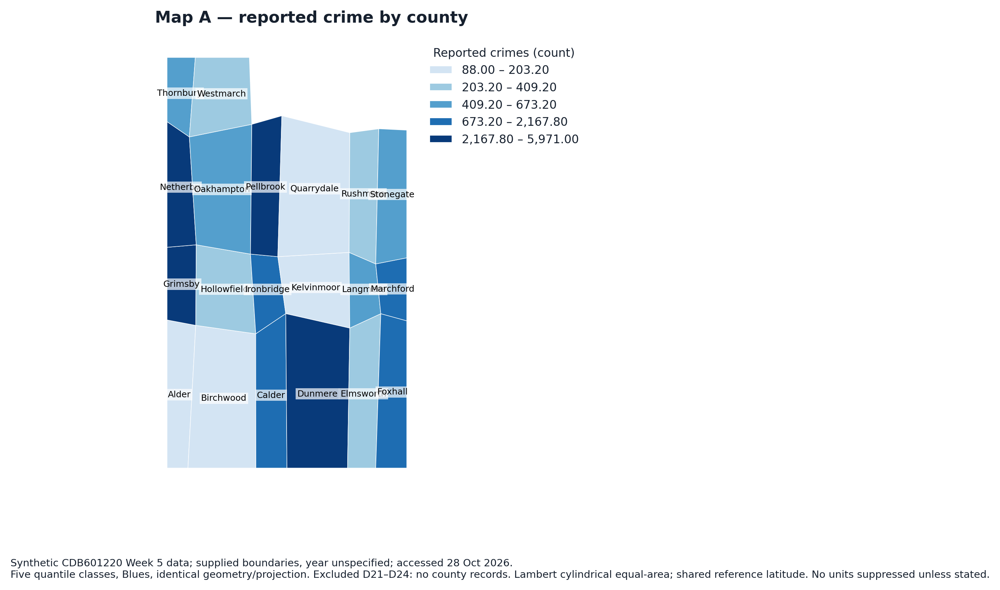

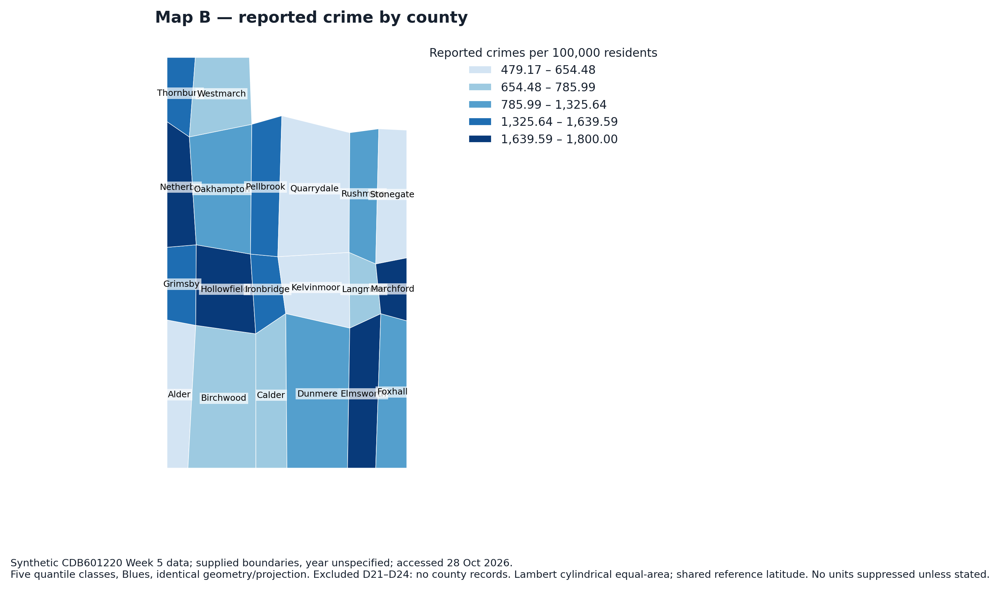

**Protocol:** Recruit at least five real readers, separately. Show only `partC_map_A.png`; ask “Which three counties would you send extra police to, and why?” Record A1–A3 and reason_A. Lock that answer. Then show `partC_map_B.png`, repeat and record B1–B3 and reason_B. Save one row per reader in `partC_reader_results.csv` and rerun this section. Map A shows reported workload, strongly related to population; Map B shows reported crimes per resident. Neither measures unreported crime or establishes how police should be allocated. The computed top-three overlap is zero, but this is **not** a reader-experiment result.

In [12]:
cf=[f for f in feats if f['code'] in set(crime.code)]
print('County table matches:',len(cf),'unmatched county records:',len(set(crime.code)-{f['code'] for f in feats}),'excluded boundary codes:',sorted({f['code'] for f in feats}-set(crime.code)))
for value,label,stem in [('crimes_reported','Reported crimes (count)','partC_map_A'),('rate','Reported crimes per 100,000 residents','partC_map_B')]:
    fig,ax=plt.subplots(figsize=(8,6)); mapplot(ax,crime,value,label,scheme='quantile',fs=cf)
    # County labels so readers can name their choices without an answer key.
    ref=np.mean([p[1] for f in cf for p in f['ring']]); names=crime.set_index('code').county
    for f in cf:
        x,y=g.equal_area_xy(*g.representative_point(f['ring']),lat_ts=ref)
        ax.text(x,y,names[f['code']],ha='center',va='center',fontsize=6,color='black',bbox={'facecolor':'white','alpha':.7,'edgecolor':'none','pad':1})
    ax.set_title('Map '+('A' if value=='crimes_reported' else 'B')+' — reported crime by county')
    finish(fig,stem,'Five quantile classes, Blues, identical geometry/projection. Excluded D21–D24: no county records. '+MAPNOTE)
print('Count/pop correlation:',crime.crimes_reported.corr(crime.population))
print('Top count:',crime.nlargest(3,'crimes_reported').county.tolist(),'Top rate:',crime.nlargest(3,'rate').county.tolist())
cr=crime.assign(count_rank=crime.crimes_reported.rank(ascending=False,method='min'),rate_rank=crime.rate.rank(ascending=False,method='min'))
print('Rank shifts >=3:',int((abs(cr.count_rank-cr.rate_rank)>=3).sum()))
cr.to_csv(ROOT/'partC_county_ranking_audit.csv',index=False)
results_path=ROOT/'partC_reader_results.csv'
if not results_path.exists():
    pd.DataFrame(columns=['reader_id','A1','A2','A3','B1','B2','B3','reason_A','reason_B','overlap_count']).to_csv(results_path,index=False)
results=pd.read_csv(results_path)
valid_names=set(crime.county)
if len(results):
    overlaps=[]
    for _,row in results.iterrows():
        aa=[row[k] for k in ['A1','A2','A3']]; bb=[row[k] for k in ['B1','B2','B3']]
        assert len(set(aa))==3 and len(set(bb))==3 and set(aa+bb)<=valid_names, 'Use three distinct exact county names per map.'
        overlaps.append(len(set(aa)&set(bb)))
    assert results.reader_id.is_unique
    results['overlap_count']=overlaps; results.to_csv(results_path,index=False)
    print('Real readers:',len(results),'Mean overlap:',results.overlap_count.mean())
    if len(results)<5: print('At least five real readers are required; collection is incomplete.')
else:
    print('PENDING: no reader responses supplied. Mean overlap is undefined, not zero. No experimental observations have been invented.')
display(Markdown('**Protocol:** Recruit at least five real readers, separately. Show only `partC_map_A.png`; ask “Which three counties would you send extra police to, and why?” Record A1–A3 and reason_A. Lock that answer. Then show `partC_map_B.png`, repeat and record B1–B3 and reason_B. Save one row per reader in `partC_reader_results.csv` and rerun this section. Map A shows reported workload, strongly related to population; Map B shows reported crimes per resident. Neither measures unreported crime or establishes how police should be allocated. The computed top-three overlap is zero, but this is **not** a reader-experiment result.'))

## Part D — Three final health figures

Region palette worst pair None (1, 6, '#0072B2', '#555555', 15.501824560157228)
Region palette worst pair deutan (3, 4, '#009E73', '#CC79A7', 7.546637952916605)
Region palette worst pair protan (1, 4, '#0072B2', '#CC79A7', 9.494498011531984)
Region palette worst pair tritan (1, 3, '#0072B2', '#009E73', 8.372200722672309)
Six hues cannot guarantee universal separation: exact region identities are available in the accessible table.
Adjacent-axis Pearson relationships:
healthcare_access cases_per_100k -0.7994925456863929
cases_per_100k urban_pct -0.6185167149312913
urban_pct median_age 0.6436292974777773
median_age gdp_pc 0.28066911953224877
Interpretation: access–incidence is inverse (crossings); incidence–urbanisation is also inverse (r=-0.619). Ranks preserve ordering, not raw distances.
Andara countries above median access and urban share AND below median incidence: ['Aldonia', 'Marnedd', 'Quenvar', 'Weslyn']
A PCP links this three-way conjunction within each country; unlinked pairwis

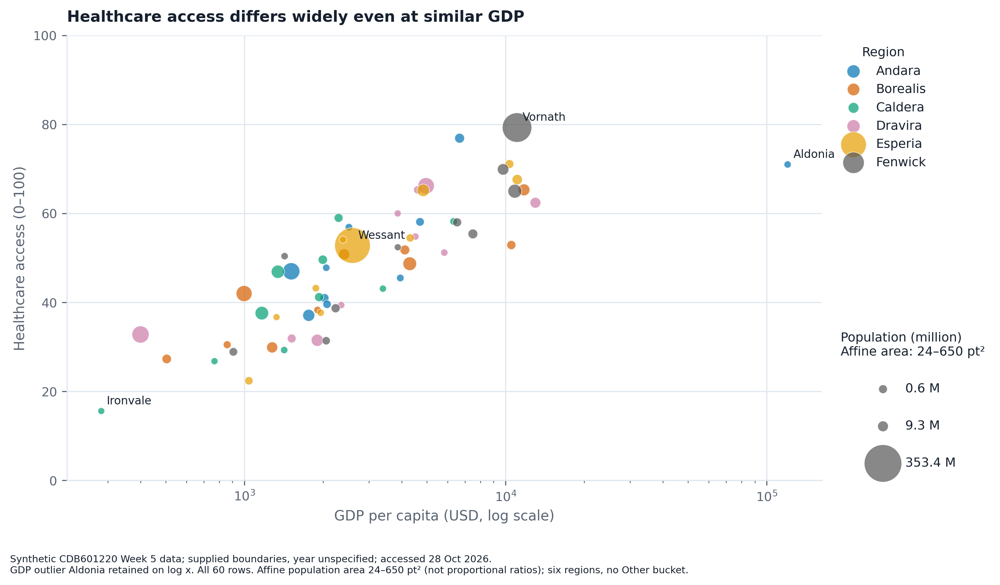

,country,region,gdp_pc,healthcare_access,pop_m
0,Aldonia,Andara,120219,71.0,1.9
48,Weslyn,Andara,4703,58.1,7.8
42,Quenvar,Andara,2513,56.9,3.0
36,Kelmara,Andara,1763,37.1,28.4
6,Galvia,Andara,1511,47.0,71.6
30,Elmvara,Andara,2026,41.0,9.2
24,Ystrad,Andara,2057,47.8,2.2
54,Corvale,Andara,2072,39.6,6.9
12,Marnedd,Andara,6667,76.9,14.6
18,Soleira,Andara,3953,45.5,2.9


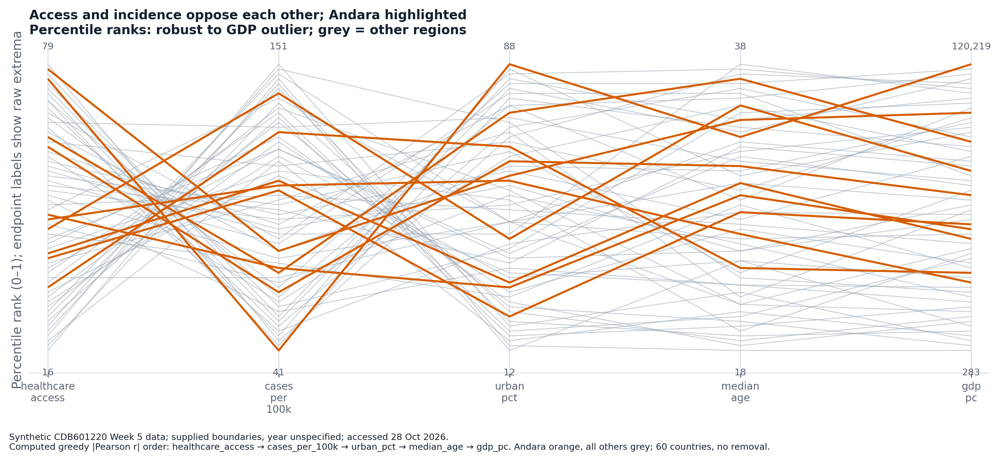

,scheme,GVF,breaks
0,equal,0.968963,"[30.440771349862256, 39.64608330358858, 48.851..."
1,quantile,0.908286,"[30.440771349862256, 43.7650794100146, 49.8131..."
2,natural,0.968963,"[30.440771349862256, 33.848314606741575, 47.54..."


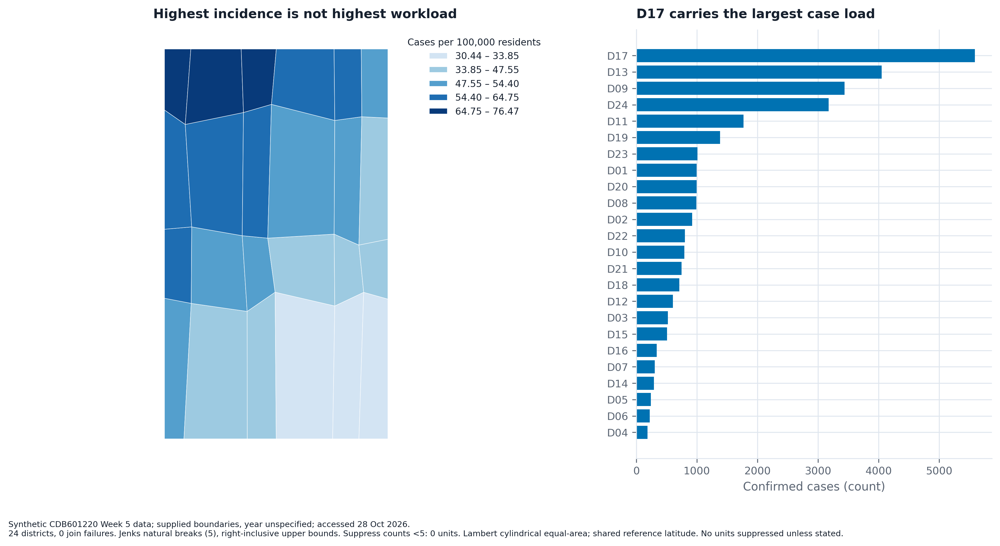

In [13]:
fig,ax=plt.subplots(figsize=(10,5.8)); bubble(ax); ax.set_title('Healthcare access differs widely even at similar GDP')
finish(fig,'partD_bubble','GDP outlier Aldonia retained on log x. All 60 rows. Affine population area 24–650 pt² (not proportional ratios); six regions, no Other bucket.')
display(h.sort_values('region')[['country','region','gdp_pc','healthcare_access','pop_m']])
h.to_csv(ROOT/'partD_accessible_data_table.csv',index=False)
colors=['#0072B2','#D55E00','#009E73','#CC79A7','#E69F00','#555555']
for kind in [None,'deutan','protan','tritan']:
    print('Region palette worst pair',kind,v.worst_pair(colors,kind=kind))
print('Six hues cannot guarantee universal separation: exact region identities are available in the accessible table.')
fig,ax=plt.subplots(figsize=(11,5)); rankpcp(ax); finish(fig,'partD_pcp','Computed greedy |Pearson r| order: '+' → '.join(chain)+'. Andara orange, all others grey; 60 countries, no removal.')
print('Adjacent-axis Pearson relationships:')
for c1,c2 in zip(chain,chain[1:]): print(c1,c2,h[c1].corr(h[c2]))
print('Interpretation: access–incidence is inverse (crossings); incidence–urbanisation is also inverse (r=-0.619). Ranks preserve ordering, not raw distances.')
# Same-row multivariate conjunction visible as complete polylines.
br=h[h.region.eq('Andara')]; med=h[cols].median()
mask=br.healthcare_access.gt(med.healthcare_access)&br.cases_per_100k.lt(med.cases_per_100k)&br.urban_pct.gt(med.urban_pct)
print('Andara countries above median access and urban share AND below median incidence:',br.loc[mask,'country'].tolist())
print('A PCP links this three-way conjunction within each country; unlinked pairwise panels do not preserve that path identity.')
scores=pd.DataFrame([{'scheme':sch,'GVF':g.gvf(d.rate,g.breaks(d.rate,sch,5)),'breaks':g.breaks(d.rate,sch,5)} for sch in ['equal','quantile','natural']]); display(scores)
fig,axs=plt.subplots(1,2,figsize=(12,6.5),gridspec_kw={'width_ratios':[1.5,1]})
# Publication rule: counts under 5 are not shown as rates. Current district data has none.
supp=d.cases.lt(5); pub=d[~supp]; fs=[f for f in feats if f['code'] in set(pub.code)]
edges=mapplot(axs[0],pub,'rate','Cases per 100,000 residents',fs=fs); axs[0].set_title('Highest incidence is not highest workload')
z=pub.sort_values('cases'); axs[1].barh(z.code,z.cases,color='#0072B2'); axs[1].set(xlabel='Confirmed cases (count)',title='D17 carries the largest case load')
finish(fig,'partD_choropleth',f'24 districts, 0 join failures. Jenks natural breaks (5), right-inclusive upper bounds. Suppress counts <5: {supp.sum()} units. '+MAPNOTE)
print('Pooled rate:',d.cases.sum()/d.population.sum()*1e5,'legend breakpoints:',edges)

## Part E — One-page justification and reproducible reports

In [14]:
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, PageBreak
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib import colors
from reportlab.lib.enums import TA_LEFT
from reportlab.lib.pagesizes import A4
from xml.sax.saxutils import escape
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from matplotlib import font_manager
pdfmetrics.registerFont(TTFont('DejaVu',font_manager.findfont('DejaVu Sans')))
pdfmetrics.registerFont(TTFont('DejaVuBold',font_manager.findfont(font_manager.FontProperties(family='DejaVu Sans',weight='bold'))))
styles=getSampleStyleSheet()
for st in styles.byName.values(): st.fontName='DejaVuBold' if st.name.startswith('Heading') else 'DejaVu'
styles['BodyText'].fontSize=9; styles['BodyText'].leading=12
styles['Heading1'].fontSize=16
E=[
('Channel budget', 'The question chooses the chart. GDP and healthcare access receive the two position channels because their relationship needs the most precise comparison; GDP is logarithmic and access keeps its 0–100 bounds. Population receives area, with an explicit affine 24–650 pt² range and a three-value legend. This makes small countries readable but compresses population ratios, so the data table provides exact values. Six region hues carry identity, not magnitude. The palette audit and accessible table disclose the limits of hue discrimination. Aldonia is retained and labelled; no country is removed and no Other bucket is needed.'),
('Parallel coordinates', 'Percentile ranks prevent one extreme GDP observation from compressing the other 59 countries, at the cost of losing gap sizes. The greedy absolute-Pearson-correlation rule fixes the order before inspection: healthcare access, case rate, urban share, median age, GDP. Grey context and orange Andara provide one pop-out per chart. Access–incidence crossings reveal the inverse relationship; incidence–urbanisation also shows an inverse association (r=-0.619). Complete paths also identify the same Andara countries with above-median access and urban share plus below-median incidence; the notebook prints their names. An unlinked scatter matrix does not identify that same-row three-way conjunction without additional linking.'),
('Spatial decisions', 'Cases divided by resident population times 100,000 estimates period incidence, while a companion zero-based sorted count bar describes workload. Five Jenks classes maximise the reported within-class variance fit among the three tested schemes; printed numeric breaks expose the decision. They are descriptive, not clinical thresholds. Lambert cylindrical equal-area uses one shared reference latitude, preserving area across districts. All 24 records join without failure. Boundaries and data are synthetic CDB601220 Week 5 materials; the source does not specify a boundary year or observation period. Access date: 28 October 2026. No real-world year is invented.'),
('Counterfactual and ethics', 'A raw-count choropleth would point at D17, D13 and D09, whereas the largest rates occur in D19, D20 and D21. Repeatedly colouring populous districts dark can stigmatise residents without establishing greater individual risk. Counts remain necessary for staffing, so both views are retained. Part C has zero supplied real-reader responses: its mean overlap is undefined and no behavioural claim is made. The deterministic top-three overlap of zero illustrates how the rankings differ; it is not experimental evidence. Publication suppresses district counts below five; none meet that rule. All 40 small-area units are retained only in the explicitly synthetic diagnostic audit, where instability is shown. A real release would need a context-specific disclosure assessment and aggregation of sensitive small counts, accepting loss of geographic detail.')]
display(Markdown('\n\n'.join('**'+t+'**\n\n'+p for t,p in E)))
def para(t): return Paragraph(escape(t),styles['BodyText'])
story=[Paragraph('Part E | Design justification',styles['Heading1'])]
for title,body in E: story.extend([Paragraph(title,styles['Heading2']),para(body)])
SimpleDocTemplate(str(ROOT/'partE_justification.pdf'),pagesize=A4,rightMargin=40,leftMargin=40,topMargin=30,bottomMargin=30).build(story)
story=[]
for n in range(1,10):
    story.extend([Paragraph(f'Part A | Case {n}',styles['Heading1']),para(notes[n]),Spacer(1,9)])
    for suffix in ['original','redesign']:
        path=OUT/f'A{n:02}_{suffix}.png'
        from PIL import Image as PILImage
        w,hh=PILImage.open(path).size; scale=min(500/w,245/hh)
        story.append(Image(str(path),width=w*scale,height=hh*scale)); story.append(Spacer(1,8))
    if n<9: story.append(PageBreak())
SimpleDocTemplate(str(ROOT/'partA_diagnosis.pdf'),pagesize=A4,rightMargin=40,leftMargin=40,topMargin=30,bottomMargin=30).build(story)
print('Reports exported. Part F is an optional real-data bonus and is not claimed or included.')

Reports exported. Part F is an optional real-data bonus and is not claimed or included.


**Channel budget**

The question chooses the chart. GDP and healthcare access receive the two position channels because their relationship needs the most precise comparison; GDP is logarithmic and access keeps its 0–100 bounds. Population receives area, with an explicit affine 24–650 pt² range and a three-value legend. This makes small countries readable but compresses population ratios, so the data table provides exact values. Six region hues carry identity, not magnitude. The palette audit and accessible table disclose the limits of hue discrimination. Aldonia is retained and labelled; no country is removed and no Other bucket is needed.

**Parallel coordinates**

Percentile ranks prevent one extreme GDP observation from compressing the other 59 countries, at the cost of losing gap sizes. The greedy absolute-Pearson-correlation rule fixes the order before inspection: healthcare access, case rate, urban share, median age, GDP. Grey context and orange Andara provide one pop-out per chart. Access–incidence crossings reveal the inverse relationship; incidence–urbanisation also shows an inverse association (r=-0.619). Complete paths also identify the same Andara countries with above-median access and urban share plus below-median incidence; the notebook prints their names. An unlinked scatter matrix does not identify that same-row three-way conjunction without additional linking.

**Spatial decisions**

Cases divided by resident population times 100,000 estimates period incidence, while a companion zero-based sorted count bar describes workload. Five Jenks classes maximise the reported within-class variance fit among the three tested schemes; printed numeric breaks expose the decision. They are descriptive, not clinical thresholds. Lambert cylindrical equal-area uses one shared reference latitude, preserving area across districts. All 24 records join without failure. Boundaries and data are synthetic CDB601220 Week 5 materials; the source does not specify a boundary year or observation period. Access date: 28 October 2026. No real-world year is invented.

**Counterfactual and ethics**

A raw-count choropleth would point at D17, D13 and D09, whereas the largest rates occur in D19, D20 and D21. Repeatedly colouring populous districts dark can stigmatise residents without establishing greater individual risk. Counts remain necessary for staffing, so both views are retained. Part C has zero supplied real-reader responses: its mean overlap is undefined and no behavioural claim is made. The deterministic top-three overlap of zero illustrates how the rankings differ; it is not experimental evidence. Publication suppresses district counts below five; none meet that rule. All 40 small-area units are retained only in the explicitly synthetic diagnostic audit, where instability is shown. A real release would need a context-specific disclosure assessment and aggregation of sensitive small counts, accepting loss of geographic detail.